# NutriWise – Multivariate Regression Models

## Project objective
NutriWise explores how demographic and body-measurement variables relate to reported daily energy intake. The model predicts **Day 1 total energy intake (`DR1TKCAL`, kcal)** from NHANES participant information.

> **Important interpretation:** `DR1TKCAL` is energy intake reported during one 24-hour dietary recall. It is **not** a medically recommended calorie target or a person's usual long-term daily requirement. A single recall can differ from usual intake.

## Dataset
Place `rhomis_africa.csv` in the same folder as this notebook. The source is the CDC's NHANES 2021–2023 survey files merged using participant ID (`SEQN`).

This notebook:
1. inspects and cleans the data;
2. explores relationships using plots;
3. prepares numeric and categorical features without test-data leakage;
4. trains and compares four regression models;
5. tunes `SGDRegressor` and plots its train/test loss curve;
6. saves the best complete preprocessing-and-model pipeline as `best_model.pkl`.


In [1]:
# 1. Imports and load dataset
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np  # pyright: ignore[reportMissingImports]
import pandas as pd # pyright: ignore[reportMissingModuleSource]
import matplotlib.pyplot as plt # pyright: ignore[reportMissingModuleSource]
import seaborn as sns # pyright: ignore[reportMissingModuleSource]
import joblib # pyright: ignore[reportMissingImports]

from sklearn.model_selection import train_test_split, ParameterGrid # pyright: ignore[reportMissingModuleSource]
from sklearn.compose import ColumnTransformer # pyright: ignore[reportMissingModuleSource]
from sklearn.pipeline import Pipeline # pyright: ignore[reportMissingModuleSource]
from sklearn.preprocessing import OneHotEncoder, StandardScaler # pyright: ignore[reportMissingModuleSource]
from sklearn.impute import SimpleImputer # pyright: ignore[reportMissingModuleSource]
from sklearn.linear_model import SGDRegressor, LinearRegression # pyright: ignore[reportMissingModuleSource]
from sklearn.tree import DecisionTreeRegressor # pyright: ignore[reportMissingModuleSource]
from sklearn.ensemble import RandomForestRegressor # pyright: ignore[reportMissingModuleSource]
from sklearn.metrics import mean_squared_error # pyright: ignore[reportMissingModuleSource]
from sklearn.base import clone # pyright: ignore[reportMissingModuleSource]

DATA_PATH = Path("rhomis_africa.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Place rhomis_africa.csv in the same folder as this notebook."
    )

df = pd.read_csv(DATA_PATH, low_memory=False)
print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (11010, 53)


,ID_PROJ,ID_COUNTRY,YEAR,ITERATION,SURVEY_ID,ID_HH,GPS_LAT,GPS_LON,GPS_ALT,Country,...,value_livestock_prod_consumed_USD_PPP_pHH_Yr,Market_Orientation,Livestock_Orientation,Food_Availability_kCal_MAE_day,Food_Self_Sufficiency_kCal_MAE_day,NrofMonthsWildFoodCons,GHGEmissions,Gender_MaleControl,Gender_FemaleControl,NFertInput
0,CFM,TZ,2015,1,TZ_CFM_2015,TZ_2015_CFM_1_1,NaN,NaN,NaN,Tanzania,...,0.000000,1.000000,0.049505,3650.565755,0.000000,0,NaN,0.000000,1.000000,NaN
1,CFM,TZ,2015,1,TZ_CFM_2015,TZ_2015_CFM_2_1,NaN,NaN,NaN,Tanzania,...,0.000000,1.000000,0.000000,3632.448997,0.000000,4,143.934000,0.499999,0.500001,75.0
2,CFM,TZ,2015,1,TZ_CFM_2015,TZ_2015_CFM_3_1,NaN,NaN,NaN,Tanzania,...,0.000000,1.000000,0.129870,5314.779021,1750.000000,1,3248.700905,1.000000,0.000000,20.0
3,CFM,TZ,2015,1,TZ_CFM_2015,TZ_2015_CFM_4_1,NaN,NaN,NaN,Tanzania,...,0.000000,NaN,NaN,257.234727,257.234727,0,887.156057,NaN,NaN,15.0
4,CFM,TZ,2015,1,TZ_CFM_2015,TZ_2015_CFM_5_1,NaN,NaN,NaN,Tanzania,...,23.102694,0.931377,0.695041,925.310354,22.070240,0,14275.030776,1.000000,0.000000,50.0


## 2. Inspect data quality

The uploaded file contains 4,798 rows and 18 columns (17 candidate inputs plus one target). The minimum assignment requirement is 1,000 rows, at least 8 feature columns, and a mixture of numeric and categorical features.

NHANES special missing values can sometimes appear as extremely small floating-point values after reading SAS transport files. We convert these to missing values before modelling.


In [2]:


print("Shape:", df.shape)
print("\nData types:")
display(df.dtypes.to_frame("dtype"))
print("\nMissing values:")
display(df.isna().sum().to_frame("missing_count"))
print("\nMissing-value percentage:")
display((df.isna().mean() * 100).round(1).to_frame("missing_percent"))


Shape: (11010, 53)

Data types:


,dtype
ID_PROJ,str
ID_COUNTRY,str
YEAR,int64
ITERATION,int64
SURVEY_ID,str
ID_HH,str
GPS_LAT,float64
GPS_LON,float64
GPS_ALT,float64
Country,str



Missing values:


,missing_count
ID_PROJ,0
ID_COUNTRY,0
YEAR,0
ITERATION,0
SURVEY_ID,0
ID_HH,0
GPS_LAT,1990
GPS_LON,1990
GPS_ALT,1990
Country,0



Missing-value percentage:


,missing_percent
ID_PROJ,0.0
ID_COUNTRY,0.0
YEAR,0.0
ITERATION,0.0
SURVEY_ID,0.0
ID_HH,0.0
GPS_LAT,18.1
GPS_LON,18.1
GPS_ALT,18.1
Country,0.0


## 3. Feature selection and cleaning

### Selected target
- `DR1TKCAL`: total energy intake from the Day 1 dietary recall, in kilocalories.

### Selected input features (10)
- Numeric: `RIDAGEYR`, `DMDHHSIZ`, `INDFMPIR`, `BMXHT`, `BMXWT`, `BMXBMI`, `BMXWAIST`
- Categorical: `RIAGENDR`, `RIDRETH3`, `DMDEDUC2`

### Columns excluded and why
- `PAD790Q`, `PAD790U`, `PAD800`, `PAD810Q`, `PAD810U`, `PAD820`, `PAD680`: physical-activity questionnaire fields. Several have substantial missingness, mixed unit coding, or special response codes. They are not needed because the selected 10 features already exceed the assignment's minimum of 8.
- `SEQN`: participant identifier, if present, is not a meaningful predictor and must not be used as a feature.
- Any dietary nutrient totals other than the target are excluded to avoid giving the model other measurements of the same food intake that could cause target leakage.

We keep categorical code columns as categories rather than treating their numeric codes as continuous measurements. Missing predictor values will be imputed inside the preprocessing pipeline. The target is never imputed.


In [3]:
TARGET = "Food_Availability_kCal_MAE_day"

numeric_features = [
    "HHsizemembers", "LandCultivated", "LivestockHoldings",
    "NrofMonthsFoodInsecure", "NrofMonthsWildFoodCons", "Gender_FemaleControl"
]
categorical_features = ["Country", "HouseholdType", "Head_EducationLevel", "HFIAS_status"]
features = numeric_features + categorical_features

required = features + [TARGET]
missing_columns = [c for c in required if c not in df.columns]
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

# Remove rows with a missing target; never impute the target.
model_df = df[required].copy()
model_df = model_df.dropna(subset=[TARGET])

# Remove impossible/invalid negative target values if any.
model_df = model_df[model_df[TARGET] >= 0].copy()

rows_before = len(model_df)

# Keep only realistic calorie values
model_df = model_df[model_df[TARGET].between(100, 50000)]

# Keep only realistic household sizes
model_df = model_df[model_df["HHsizemembers"].between(1, 30)]

# Keep realistic land sizes, and rows where land is missing
land = model_df["LandCultivated"]
model_df = model_df[land.between(0, 50) | land.isna()]

# Keep only realistic livestock holdings
model_df = model_df[model_df["LivestockHoldings"].between(0, 50)].copy()

print("Rows before:", rows_before, "| after:", len(model_df), "| removed:", rows_before - len(model_df))

# Keep categories as text, with missing values as np.nan so SimpleImputer can fill them.
for col in categorical_features:
    model_df[col] = model_df[col].astype(object).where(model_df[col].notna(), np.nan)

X = model_df[features]
y = model_df[TARGET].astype(float)

print(f"Rows available for modelling: {len(model_df):,}")
print(f"Number of input features: {len(features)}")
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Target:", TARGET)
assert len(model_df) >= 1000, "Dataset must contain at least 1,000 usable rows."
assert len(features) >= 8, "At least 8 input features are required."


Rows before: 10944 | after: 9479 | removed: 1465
Rows available for modelling: 9,479
Number of input features: 10
Numeric features: ['HHsizemembers', 'LandCultivated', 'LivestockHoldings', 'NrofMonthsFoodInsecure', 'NrofMonthsWildFoodCons', 'Gender_FemaleControl']
Categorical features: ['Country', 'HouseholdType', 'Head_EducationLevel', 'HFIAS_status']
Target: Food_Availability_kCal_MAE_day


## 4. Exploratory data analysis

### Plot 1 – Correlation heatmap
The heatmap shows the direction and strength of linear relationships among numeric variables and the target. Stronger correlations can help identify useful candidate predictors, while highly correlated predictors may contain overlapping information. Correlation does not prove causation.

### Plot 2 – Target distribution
The histogram shows how reported Day 1 calorie intake is distributed. A long right tail would indicate that a small number of participants reported much higher energy intake; this matters because squared-error metrics are sensitive to large errors and outliers.


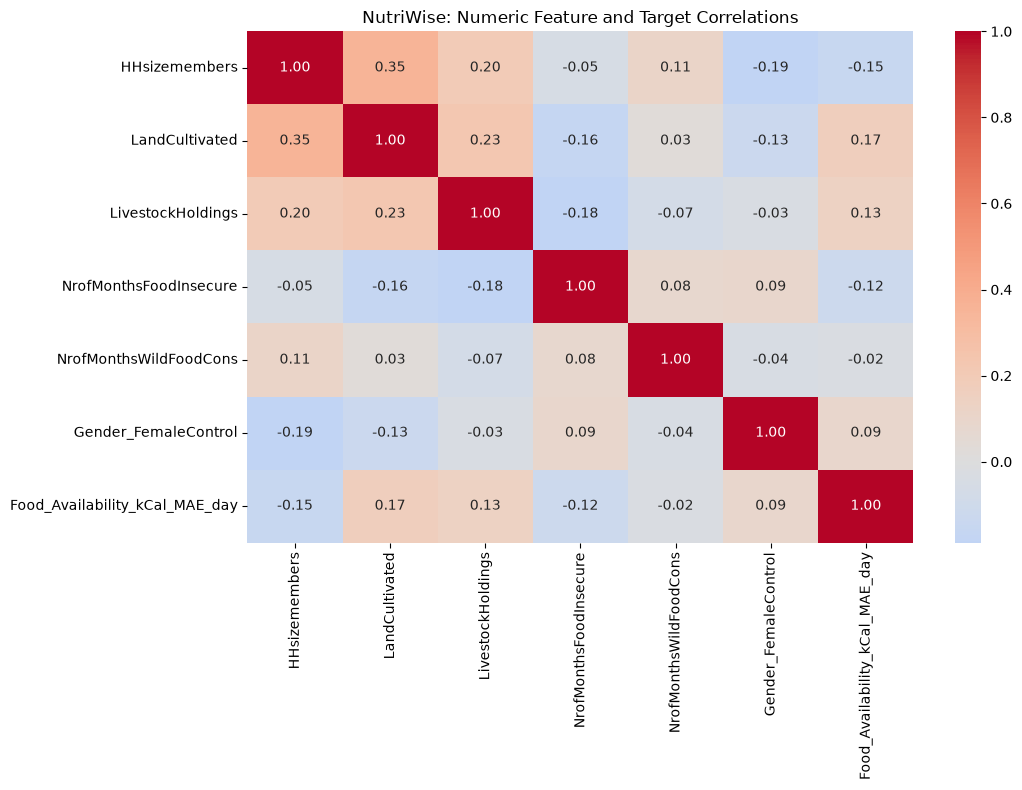

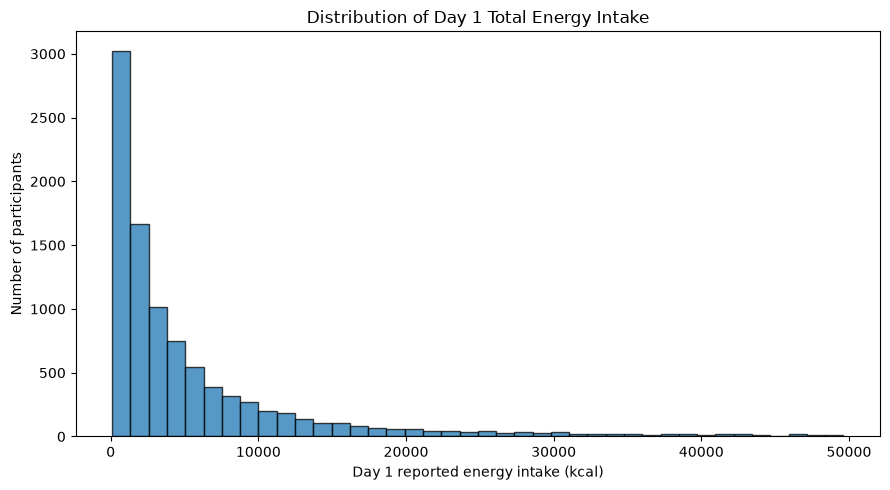

In [4]:
# Plot 1: correlation heatmap (numeric columns only)
numeric_for_corr = model_df[numeric_features + [TARGET]].copy()
corr = numeric_for_corr.corr(numeric_only=True)

plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("NutriWise: Numeric Feature and Target Correlations")
plt.tight_layout()
plt.show()

# Plot 2: target distribution
plt.figure(figsize=(9, 5))
plt.hist(y, bins=40, edgecolor="black", alpha=0.75)
plt.xlabel("Day 1 reported energy intake (kcal)")
plt.ylabel("Number of participants")
plt.title("Distribution of Day 1 Total Energy Intake")
plt.tight_layout()
plt.show()


## 5. Required scatter plots: before and after

We select the numeric feature with the largest absolute Pearson correlation with `DR1TKCAL`. The first plot shows the raw relationship. The second adds a fitted one-feature linear regression line. This one-feature model is only for visualization; it is not one of the four multivariate models being compared.


Most correlated numeric feature: LandCultivated
Correlation with target: 0.166


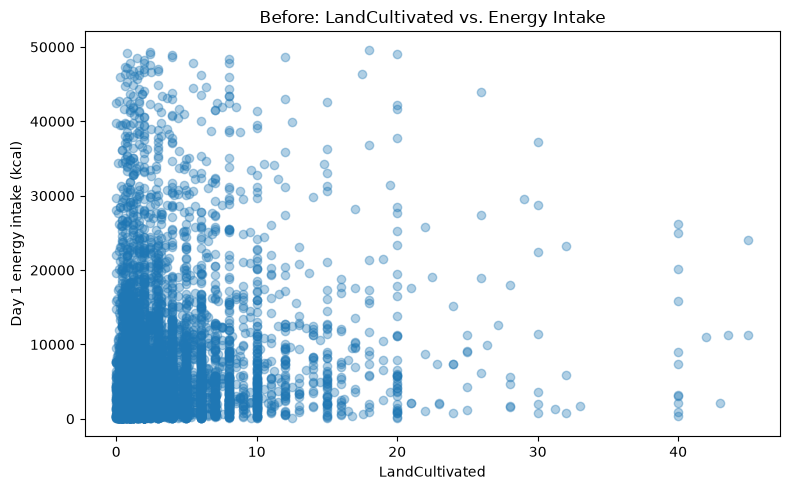

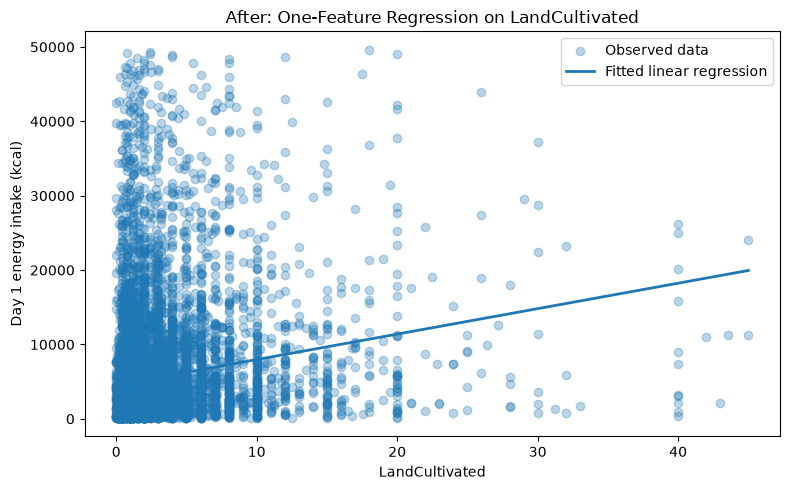

In [5]:
# Find numeric feature most correlated with the target.
target_corr = corr[TARGET].drop(TARGET).dropna()
best_scatter_feature = target_corr.abs().idxmax()
print("Most correlated numeric feature:", best_scatter_feature)
print("Correlation with target:", round(target_corr[best_scatter_feature], 3))

scatter_data = model_df[[best_scatter_feature, TARGET]].dropna()

# Scatter plot before fitting
plt.figure(figsize=(8, 5))
plt.scatter(scatter_data[best_scatter_feature], scatter_data[TARGET], alpha=0.35)
plt.xlabel(best_scatter_feature)
plt.ylabel("Day 1 energy intake (kcal)")
plt.title(f"Before: {best_scatter_feature} vs. Energy Intake")
plt.tight_layout()
plt.show()

# Fit a one-feature regression line for visualization only
one_feature_model = LinearRegression()
one_feature_model.fit(scatter_data[[best_scatter_feature]], scatter_data[TARGET])

x_line = np.linspace(
    scatter_data[best_scatter_feature].min(),
    scatter_data[best_scatter_feature].max(),
    200
).reshape(-1, 1)
y_line = one_feature_model.predict(x_line)

plt.figure(figsize=(8, 5))
plt.scatter(scatter_data[best_scatter_feature], scatter_data[TARGET], alpha=0.30, label="Observed data")
plt.plot(x_line, y_line, linewidth=2, label="Fitted linear regression")
plt.xlabel(best_scatter_feature)
plt.ylabel("Day 1 energy intake (kcal)")
plt.title(f"After: One-Feature Regression on {best_scatter_feature}")
plt.legend()
plt.tight_layout()
plt.show()


## 6. Train/test split and preprocessing

We use an 80/20 train/test split. Numeric columns are median-imputed and standardized. Categorical columns are imputed with their most frequent value and one-hot encoded.

**Leakage prevention:** the preprocessing transformer is fitted only on training data. The test set is transformed using the already-fitted training transformer.


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

numeric_preprocess = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocess = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_preprocess, numeric_features),
    ("categorical", categorical_preprocess, categorical_features)
])

# Fit only on training rows.
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training rows:", X_train_processed.shape[0])
print("Test rows:", X_test_processed.shape[0])
print("Processed feature count:", X_train_processed.shape[1])


Training rows: 7583
Test rows: 1896
Processed feature count: 61


## 7. Tune SGDRegressor using a validation split

`SGDRegressor` is the gradient-descent model. We tune:
- `eta0`: initial learning rate;
- `alpha`: L2 regularization strength;
- `epochs`: number of passes through the training subset.

A validation subset is held out from the training data for choosing these settings. The final test set is reserved for the common model comparison. The loss curve below will then show train and test MSE per epoch, as required by the assignment.


In [7]:
# Split the original training partition again for hyperparameter selection.
X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train, y_train, test_size=0.20, random_state=21
)

tune_preprocessor = clone(preprocessor)
X_subtrain_p = tune_preprocessor.fit_transform(X_subtrain)
X_val_p = tune_preprocessor.transform(X_val)

param_grid = {
    "eta0": [0.001, 0.01, 0.03],
    "alpha": [0.0001, 0.001, 0.01],
    "epochs": [50, 100, 200]
}

tuning_results = []
rng = np.random.default_rng(42)

for params in ParameterGrid(param_grid):
    candidate = SGDRegressor(
        loss="squared_error",
        penalty="l2",
        alpha=params["alpha"],
        learning_rate="constant",
        eta0=params["eta0"],
        max_iter=1,
        tol=None,
        random_state=42
    )

    for epoch in range(params["epochs"]):
        order = rng.permutation(len(y_subtrain))
        candidate.partial_fit(X_subtrain_p[order], y_subtrain.iloc[order])

    val_pred = candidate.predict(X_val_p)
    val_mse = mean_squared_error(y_val, val_pred)
    tuning_results.append({**params, "validation_mse": val_mse})

tuning_table = pd.DataFrame(tuning_results).sort_values("validation_mse")
display(tuning_table.head(10))

best_params = tuning_table.iloc[0].to_dict()
best_eta0 = float(best_params["eta0"])
best_alpha = float(best_params["alpha"])
best_epochs = int(best_params["epochs"])

print("Best SGD settings:")
print({"eta0": best_eta0, "alpha": best_alpha, "epochs": best_epochs})


,alpha,epochs,eta0,validation_mse
21,0.0100,100,0.001,5.070050e+07
6,0.0001,200,0.001,5.074430e+07
15,0.0010,200,0.001,5.083814e+07
9,0.0010,50,0.001,5.088285e+07
0,0.0001,50,0.001,5.096594e+07
3,0.0001,100,0.001,5.106082e+07
12,0.0010,100,0.001,5.108411e+07
18,0.0100,50,0.001,5.109969e+07
24,0.0100,200,0.001,5.110715e+07
13,0.0010,100,0.010,5.220226e+07


Best SGD settings:
{'eta0': 0.001, 'alpha': 0.01, 'epochs': 100}


## 8. Train SGDRegressor with `partial_fit` and plot its loss curve

The preprocessor is now fitted on the complete training partition only. We train one epoch at a time with `partial_fit`, recording train and test MSE after every epoch.


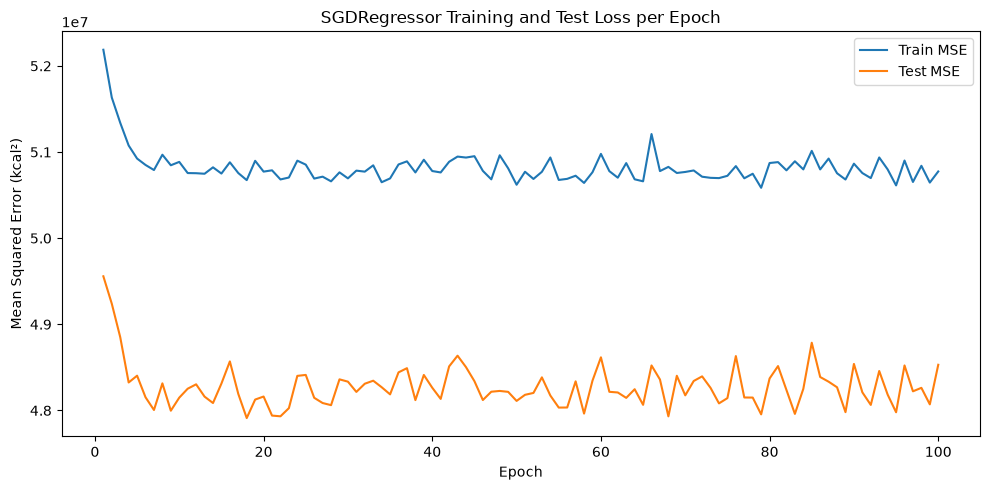

In [8]:
# Refit preprocessing on all training data only.
final_preprocessor = clone(preprocessor)
X_train_p = final_preprocessor.fit_transform(X_train)
X_test_p = final_preprocessor.transform(X_test)

sgd_model = SGDRegressor(
    loss="squared_error",
    penalty="l2",
    alpha=best_alpha,
    learning_rate="constant",
    eta0=best_eta0,
    max_iter=1,
    tol=None,
    random_state=42
)

train_losses = []
test_losses = []
rng = np.random.default_rng(123)

for epoch in range(best_epochs):
    order = rng.permutation(len(y_train))
    sgd_model.partial_fit(X_train_p[order], y_train.iloc[order])

    train_pred_epoch = sgd_model.predict(X_train_p)
    test_pred_epoch = sgd_model.predict(X_test_p)

    train_losses.append(mean_squared_error(y_train, train_pred_epoch))
    test_losses.append(mean_squared_error(y_test, test_pred_epoch))

plt.figure(figsize=(10, 5))
plt.plot(range(1, best_epochs + 1), train_losses, label="Train MSE")
plt.plot(range(1, best_epochs + 1), test_losses, label="Test MSE")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (kcal²)")
plt.title("SGDRegressor Training and Test Loss per Epoch")
plt.legend()
plt.tight_layout()
plt.show()

sgd_pipeline = Pipeline(steps=[
    ("preprocessor", final_preprocessor),
    ("model", sgd_model)
])


## 9. Train and compare all four regression models

All four models use the same train/test split and the same training-fitted preprocessing. We compare both training MSE and test MSE. Lower test MSE indicates better predictive performance on this held-out test set.


In [9]:
models = {
    "SGDRegressor": sgd_pipeline,
    "LinearRegression": Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("model", LinearRegression())
    ]),
    "DecisionTreeRegressor": Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("model", DecisionTreeRegressor(random_state=42, min_samples_leaf=5))
    ]),
    "RandomForestRegressor": Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("model", RandomForestRegressor(
            n_estimators=100,
            random_state=42,
            min_samples_leaf=10,
            n_jobs=-1
        ))
    ])
}

results = []
for name, model in models.items():
    if name != "SGDRegressor":
        model.fit(X_train, y_train)

    train_prediction = model.predict(X_train)
    test_prediction = model.predict(X_test)

    results.append({
        "Model": name,
        "Train MSE": mean_squared_error(y_train, train_prediction),
        "Test MSE": mean_squared_error(y_test, test_prediction)
    })

results_df = pd.DataFrame(results).sort_values("Test MSE").reset_index(drop=True)
display(results_df.style.format({
    "Train MSE": "{:,.2f}",
    "Test MSE": "{:,.2f}"
}))

best_model_name = results_df.loc[0, "Model"]
best_model = models[best_model_name]

print(f"Best model based on the lowest test MSE: {best_model_name}")
print(f"Lowest test MSE: {results_df.loc[0, 'Test MSE']:,.2f}")


,Model,Train MSE,Test MSE
0,RandomForestRegressor,"35,205,877.09","44,627,858.79"
1,LinearRegression,"50,179,948.33","47,959,388.61"
2,SGDRegressor,"50,774,571.80","48,530,295.32"
3,DecisionTreeRegressor,"27,527,030.68","58,861,006.92"


Best model based on the lowest test MSE: RandomForestRegressor
Lowest test MSE: 44,627,858.79


## 10. Interpret the model comparison

Use the comparison table above to explain:
- which model has the lowest test MSE;
- whether any model appears to overfit (very low train MSE but much higher test MSE);
- whether the linear models perform competitively with the tree-based models;
- how the dataset's limited feature set, missing values, one-day dietary recall, and possible outliers may affect prediction accuracy.

Do not claim that the model measures a person's usual diet or recommends how many calories they should eat. The target is one-day self-reported dietary intake.


## 11. Save the best complete model pipeline

The saved pipeline includes preprocessing and the fitted estimator. This is important because the API must apply exactly the same imputing, scaling and categorical encoding steps to new user inputs.


In [10]:
MODEL_PATH = Path("../API/best_model.pkl")
joblib.dump(best_model, MODEL_PATH, compress=3)
print(f"Saved best model pipeline to: {MODEL_PATH.resolve()}")


def load_and_predict(row, model_path=MODEL_PATH):
    """Load the saved pipeline and predict the target for a one-row DataFrame."""
    loaded_model = joblib.load(model_path)
    return float(loaded_model.predict(row)[0])


# Demonstrate the function on one held-out test row.
one_test_row = X_test.iloc[[0]]
actual_value = y_test.iloc[0]
predicted_value = load_and_predict(one_test_row)

print(f"Actual food availability: {actual_value:,.1f} kcal per adult per day")
print(f"Predicted food availability: {predicted_value:,.1f} kcal per adult per day")

Saved best model pipeline to: C:\Users\HP\Desktop\Summative---Regression-Analysis\summative\API\best_model.pkl


Actual food availability: 6,099.0 kcal per adult per day
Predicted food availability: 5,244.2 kcal per adult per day


## 12. Limitations and responsible use

1. The data is an African dataset: RHoMIS surveys of farm households in 11 countries (Burkina Faso, Burundi, DRC, Ethiopia, Ghana, Kenya, Malawi, Mali, Tanzania, Uganda and Zambia), collected from 2015 to 2018. Rwanda is not included, so the model needs validation on Rwandan data before it is used there.
2. The countries are not equally represented. Burkina Faso and Tanzania make up about half of the rows, while Uganda and Malawi have fewer than 160 each, so predictions may be less reliable for the smaller groups.
3. `Food_Availability_kCal_MAE_day` estimates the calories available per adult per day in a household. It does not measure what any one person ate.
4. The survey answers are self-reported and can contain recall and reporting errors. The data also has missing values and extreme outliers.
5. This model is for a machine-learning coursework demonstration and nutrition awareness, not diagnosis or personalized medical advice.
6. A low MSE does not establish that the model is suitable for real-world decisions. Further validation and domain expertise would be required first.